# Predicción de la volatilidad con ARCH/GARCH

In [2]:
import datetime as dt
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.graphics import tsaplots
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.diagnostic import het_arch
import statsmodels.graphics.tsaplots as sgt
from arch import arch_model
from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [3]:
file_path = "BTC-Daily.csv"
data = pd.read_csv(file_path)
data = data[["date","close"]]
data.date = pd.to_datetime(data.date)
data.set_index("date", inplace = True)
data.index = data.index.sort_values()
data.head()

,close
date,
2014-11-28,43185.48
2014-11-29,43178.98
2014-11-30,37712.68
2014-12-01,39146.66
2014-12-02,39231.64


Calculamos la rentabilidad del bitcoin.

Visualizamos la serie

<Axes: xlabel='date'>

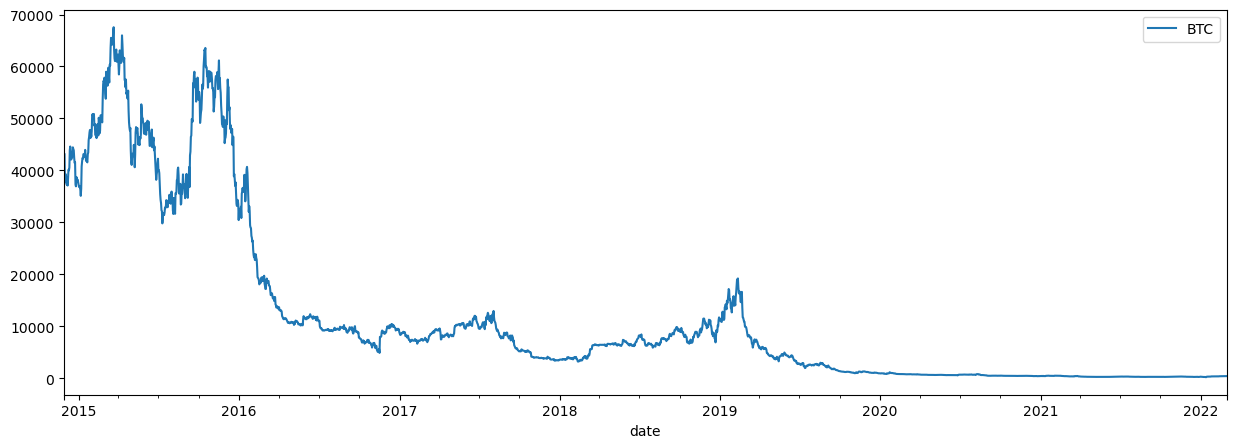

In [4]:
data.plot(y="close", label = "BTC", figsize=(15,5))

Antes de analizar el residuo voy a asegurarme que no tiene componentes estacional.

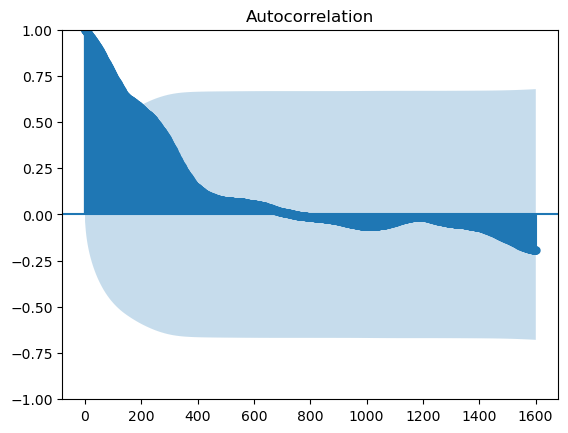

In [5]:
tsaplots.plot_acf(data.close, lags=1600)
plt.show()

Parece que la serie no tiene no tiene componente estacional por lo que para obtener el residuo tendré que eliminar únicamente la tendencia.

<Axes: xlabel='date'>

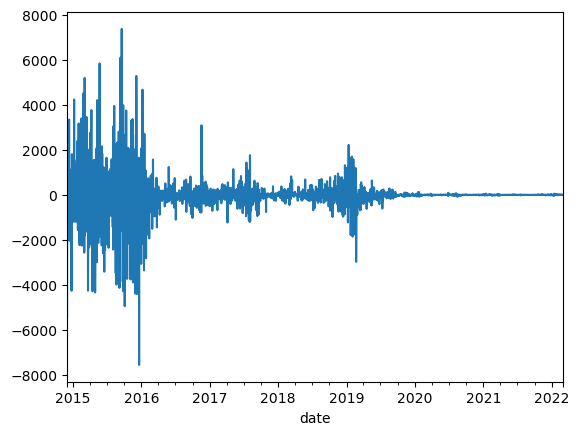

In [6]:
# Elimino la tendencia de la serie mediante diferenciación
residuo_diff = data.close.diff().dropna()
residuo_diff.plot()


In [20]:
# Método 2: eliminamos la media móvil
media_movil = data.close.rolling(window=60).mean()
residuo = data.close - media_movil

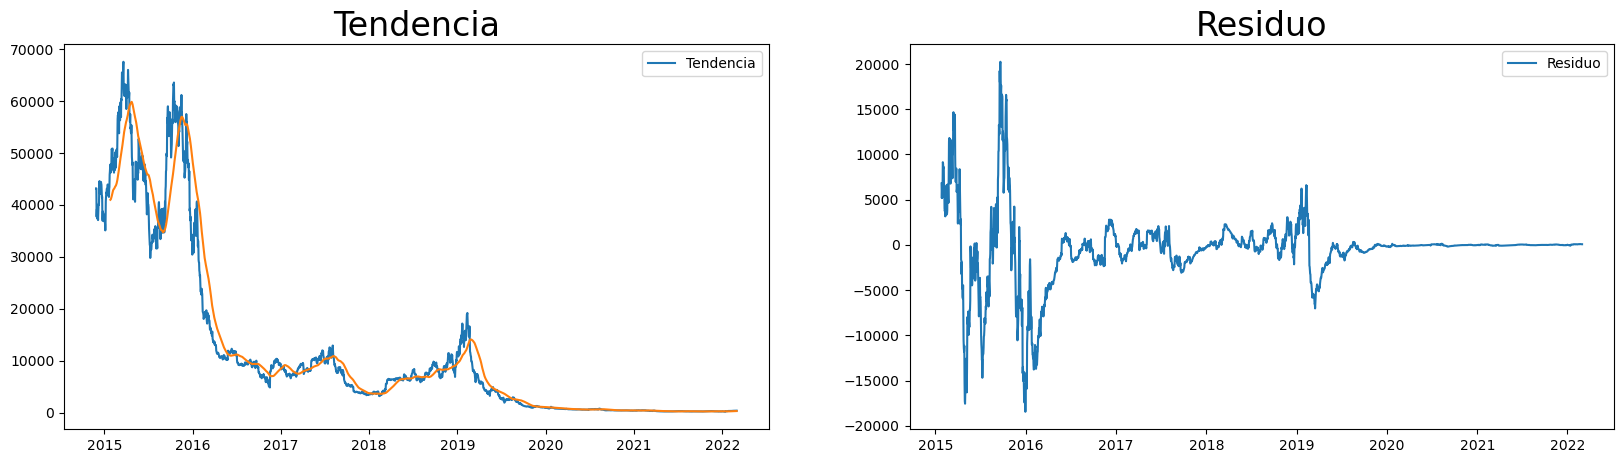

In [26]:
fig, ax = plt.subplots(1,2, figsize=(20, 5))

ax[0].plot(data.close)
ax[0].plot(media_movil)
ax[0].set_title("Tendencia", size = 24)
ax[0].legend(["Tendencia"])

ax[1].plot(residuo)
ax[1].set_title("Residuo", size = 24)
ax[1].legend(["Residuo"])

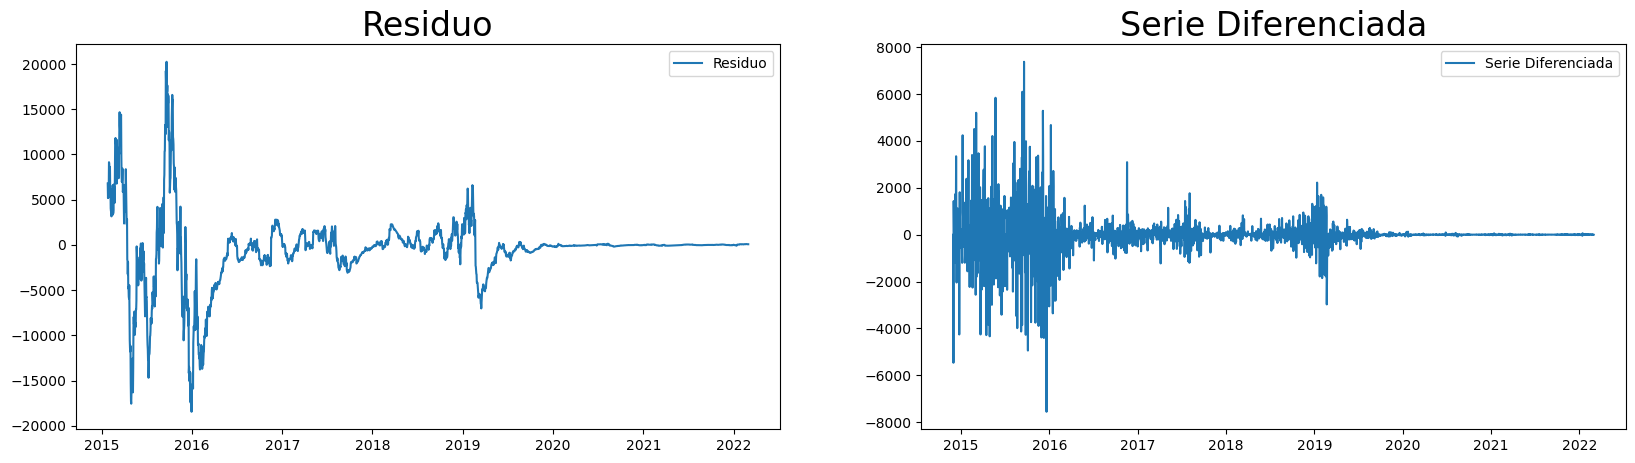

In [27]:
fig, ax = plt.subplots(1,2, figsize=(20, 5))

ax[0].plot(residuo)
ax[0].set_title("Residuo", size = 24)
ax[0].legend(["Residuo"])

ax[1].plot(residuo_diff)
ax[1].set_title("Serie Diferenciada", size = 24)
ax[1].legend(["Serie Diferenciada"])

In [9]:
adf_result = adfuller(residuo_diff.dropna())
kpss_result = kpss(residuo_diff.dropna())
print("ADF p-valor",adf_result[1])
print("KPSS p-valor", kpss_result[1])

ADF p-valor 9.979366267170811e-14
KPSS p-valor 0.1


C:\Users\icalvo\AppData\Local\Temp\ipykernel_25520\712024024.py:2: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  kpss_result = kpss(residuo_diff.dropna())


Si graficamos el cuadrado del residuo podremos comprobar visualmente los periodos de alta y baja volatilidad.

In [15]:
residuo2 = residuo_diff.mul(residuo_diff)

<Axes: xlabel='date'>

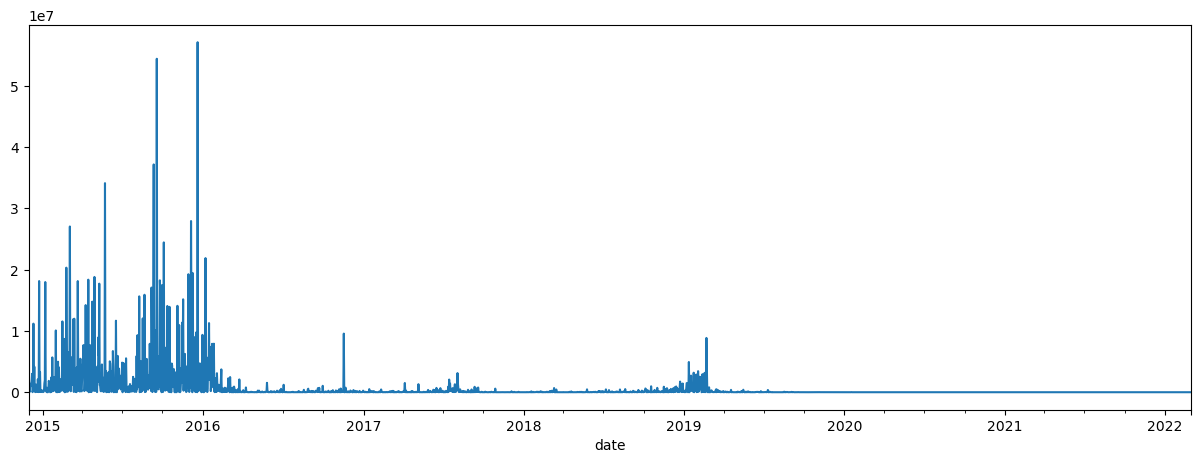

In [16]:
residuo2.plot(label = "Volatilidad", figsize=(15,5))

Calculamos las volatilidades históricas en primer lugar

In [13]:
# Calculate daily std of returns
std_daily = residuo_diff.std()
print(f'Daily volatility: {round(std_daily,2)}%')

# Convert daily volatility to monthly volatility
std_monthly = np.sqrt(21) * std_daily
print(f'\nMonthly volatility: {round(std_monthly,2)}%')

# Convert daily volatility to annaul volatility
std_annual = np.sqrt(252) * std_daily
print(f'\nAnnual volatility: {round(std_annual,2)}%')

Daily volatility: 799.0%

Monthly volatility: 3661.49%

Annual volatility: 12683.78%


Comprobamos si la rentabilidad tiene estructura.

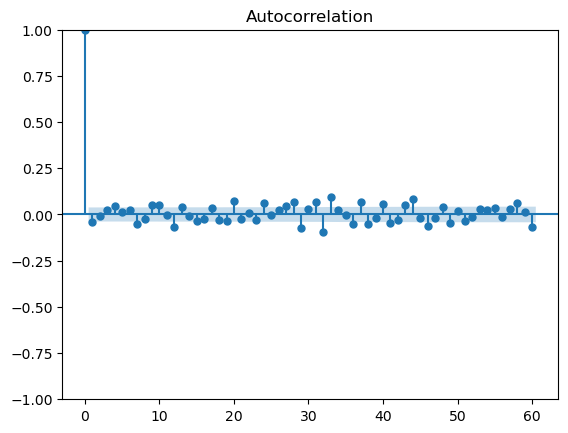

In [14]:
tsaplots.plot_acf(residuo_diff, lags=60);

No se observa ningún patrón evitende en el rendimiento de la serie por lo que trabajaremos directamente con la variable.

Dibujamos los diagramas de autocorrelación y autocorrelación parcial del rendimiento al cuadrado.


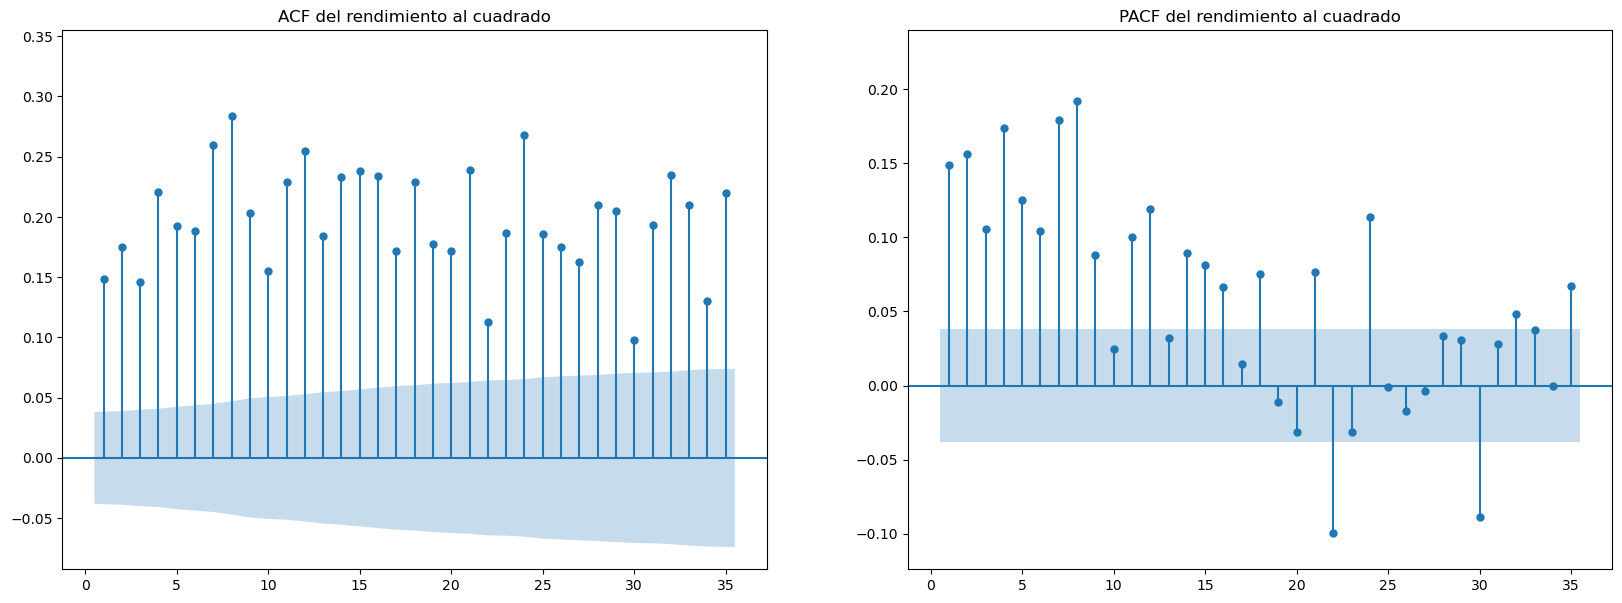

In [17]:

plt.rcParams["figure.figsize"] = (20, 7)
fig, ax = plt.subplots(1,2)

sgt.plot_acf(residuo2,ax=ax[0], zero=False,auto_ylims=True, title="ACF del rendimiento al cuadrado")
sgt.plot_pacf(residuo2,ax=ax[1],zero=False,auto_ylims=True,title="PACF del rendimiento al cuadrado");

## Modelización de la volatilidad

### GARCH (1,1)

In [49]:
# GARCH(1,1)
garchm = arch_model(residuo_diff, p = 1, q = 1,
                      mean = 'constant', vol = 'GARCH', dist = 'normal')

# Fit the model
gm_result = garchm.fit(update_freq = 4)

Iteration:      4,   Func. Count:     22,   Neg. LLF: 18820.835939903052
Iteration:      8,   Func. Count:     42,   Neg. LLF: 18818.04566781131
Iteration:     12,   Func. Count:     62,   Neg. LLF: 18817.98614443702
Iteration:     16,   Func. Count:     82,   Neg. LLF: 18815.28918393507
Iteration:     20,   Func. Count:    102,   Neg. LLF: 18340.45976557552
Iteration:     24,   Func. Count:    132,   Neg. LLF: 53377.62560917389
Iteration:     28,   Func. Count:    163,   Neg. LLF: 106043.82481174337
Iteration:     32,   Func. Count:    187,   Neg. LLF: 16820.690856370446
Iteration:     36,   Func. Count:    207,   Neg. LLF: 16820.648684535383
Optimization terminated successfully    (Exit mode 0)
            Current function value: 16820.64867761162
            Iterations: 39
            Function evaluations: 216
            Gradient evaluations: 38


c:\Users\icalvo\.conda\envs\ds3\Lib\site-packages\arch\univariate\base.py:694: DataScaleWarning: y is poorly scaled, which may affect convergence of the optimizer when
estimating the model parameters. The scale of y is 6.382e+05. Parameter
estimation work better when this value is between 1 and 1000. The recommended
rescaling is 0.1 * y.

This warning can be disabled by either rescaling y before initializing the
model or by setting rescale=False.

  self._check_scale(resids)


In [44]:
print(gm_result.summary())

                     Constant Mean - GARCH Model Results                      
Dep. Variable:                  close   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -16811.2
Distribution:                  Normal   AIC:                           33632.4
Method:            Maximum Likelihood   BIC:                           33661.8
                                        No. Observations:                 2649
Date:                Wed, Sep 30 2026   Df Residuals:                     2648
Time:                        17:48:03   Df Model:                            1
                               Mean Model                               
                 coef    std err          t      P>|t|  95.0% Conf. Int.
------------------------------------------------------------------------
mu            -0.2000      0.277     -0.723      0.470 [ -0.742,  0.34

### GARCH (1,2)

In [50]:
# GARCH(1,2)
garchm = arch_model(residuo_diff, p = 1, q = 2,
                      mean = 'constant', vol = 'GARCH', dist = 'normal')

# Fit the model
gm_result = garchm.fit(update_freq = 4)

Iteration:      4,   Func. Count:     28,   Neg. LLF: 24805.862756577088
Iteration:      8,   Func. Count:     55,   Neg. LLF: 18736.44120411881
Iteration:     12,   Func. Count:     79,   Neg. LLF: 18735.302938508074
Iteration:     16,   Func. Count:    103,   Neg. LLF: 18735.085078410204
Iteration:     20,   Func. Count:    127,   Neg. LLF: 18569.258168257278
Iteration:     24,   Func. Count:    164,   Neg. LLF: 16924.380104535136
Iteration:     28,   Func. Count:    188,   Neg. LLF: 16829.463754308268
Iteration:     32,   Func. Count:    212,   Neg. LLF: 16811.963469903127
Iteration:     36,   Func. Count:    236,   Neg. LLF: 16811.212780097536
Iteration:     40,   Func. Count:    260,   Neg. LLF: 16811.194156254256
Optimization terminated successfully    (Exit mode 0)
            Current function value: 16811.194156254256
            Iterations: 41
            Function evaluations: 265
            Gradient evaluations: 41


c:\Users\icalvo\.conda\envs\ds3\Lib\site-packages\arch\univariate\base.py:694: DataScaleWarning: y is poorly scaled, which may affect convergence of the optimizer when
estimating the model parameters. The scale of y is 6.382e+05. Parameter
estimation work better when this value is between 1 and 1000. The recommended
rescaling is 0.1 * y.

This warning can be disabled by either rescaling y before initializing the
model or by setting rescale=False.

  self._check_scale(resids)


In [51]:
print(gm_result.summary())

                     Constant Mean - GARCH Model Results                      
Dep. Variable:                  close   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -16811.2
Distribution:                  Normal   AIC:                           33632.4
Method:            Maximum Likelihood   BIC:                           33661.8
                                        No. Observations:                 2649
Date:                Wed, Sep 30 2026   Df Residuals:                     2648
Time:                        17:50:15   Df Model:                            1
                               Mean Model                               
                 coef    std err          t      P>|t|  95.0% Conf. Int.
------------------------------------------------------------------------
mu            -0.2000      0.277     -0.723      0.470 [ -0.742,  0.34

Teniendo en cuenta la información del resumen, estamos ajustando bien el modelos de la volatilidad, pero no el de la media de la serie. Esto puede deberse al elevado choque que se aprecia en la serie. Para resolver este tipo de asimetrías utilizaremos el modelo EGARCH.

### EGARCH(1,1,1)

In [52]:
# EGARCH(1,1,1)
garchm = arch_model(residuo_diff, p = 1, q = 1, o=1,
                      mean = 'constant', vol = 'EGARCH', dist = 'normal')
# Fit the model
gm_result = garchm.fit(update_freq = 4)

Iteration:      4,   Func. Count:     30,   Neg. LLF: 301203350.47252303
Iteration:      8,   Func. Count:     62,   Neg. LLF: 27179.343691755068
Iteration:     12,   Func. Count:     87,   Neg. LLF: 18762.097756475858
Iteration:     16,   Func. Count:    113,   Neg. LLF: 18761.138117406605
Iteration:     20,   Func. Count:    143,   Neg. LLF: 18761.128400505157
Optimization terminated successfully    (Exit mode 0)
            Current function value: 18761.128346008572
            Iterations: 21
            Function evaluations: 146
            Gradient evaluations: 20


c:\Users\icalvo\.conda\envs\ds3\Lib\site-packages\arch\univariate\base.py:694: DataScaleWarning: y is poorly scaled, which may affect convergence of the optimizer when
estimating the model parameters. The scale of y is 6.382e+05. Parameter
estimation work better when this value is between 1 and 1000. The recommended
rescaling is 0.1 * y.

This warning can be disabled by either rescaling y before initializing the
model or by setting rescale=False.

  self._check_scale(resids)


In [53]:
print(gm_result.summary())

                     Constant Mean - EGARCH Model Results                     
Dep. Variable:                  close   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                     EGARCH   Log-Likelihood:               -18761.1
Distribution:                  Normal   AIC:                           37532.3
Method:            Maximum Likelihood   BIC:                           37561.7
                                        No. Observations:                 2649
Date:                Wed, Sep 30 2026   Df Residuals:                     2648
Time:                        17:51:16   Df Model:                            1
                               Mean Model                               
                 coef    std err          t      P>|t|  95.0% Conf. Int.
------------------------------------------------------------------------
mu             0.3500  4.793e-04    730.248      0.000 [  0.349,  0.35

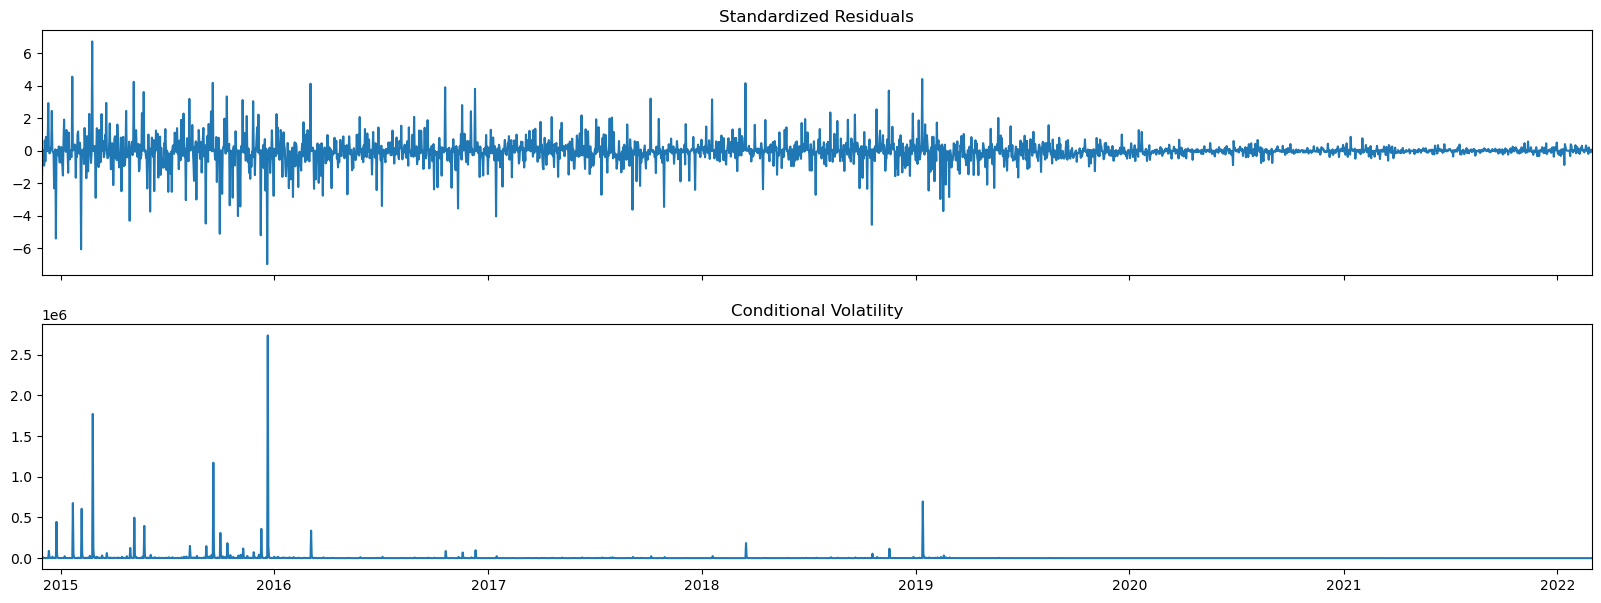

In [57]:
gm_result.plot()
plt.show()

#### Comprobación de la calidad del modelo

Vemos que el valor absoluto de t > 2 y que el p-valor < 0.05 en todos los caso, por lo que podríamos aceptar todos los coeficientes como buenos ajustes. Comprobemos que el residuo del ajuste no tiene autocorrelación.

In [58]:
gm_std_resid = gm_result.std_resid

In [59]:
lm_test = het_arch(gm_std_resid)

print("Resultados del ARCH test:")
print(f"Estadístico LM: {lm_test[0]:.4f}")
print(f"P-valor LM: {lm_test[1]:.4f}")
print(f"Estadístico F: {lm_test[2]:.4f}")
print(f"P-valor F: {lm_test[3]:.4f}")

Resultados del ARCH test:
Estadístico LM: 54.8981
P-valor LM: 0.0000
Estadístico F: 5.5831
P-valor F: 0.0000


No eliminar bien la heterocedasticidad. Seguimos probando otros modelos

### EGARCH (1,2,2)

In [82]:
# EGARCH(1,2,2)
garchm = arch_model(residuo_diff, p = 2, q = 1, o=2,
                      mean = 'constant', vol = 'EGARCH', dist = 'normal')
# Fit the model
gm_result = garchm.fit(update_freq = 4)

Iteration:      4,   Func. Count:     40,   Neg. LLF: 161158416.64296654
Iteration:      8,   Func. Count:     80,   Neg. LLF: 63435634.964278325
Iteration:     12,   Func. Count:    120,   Neg. LLF: 18630.530964482412
Iteration:     16,   Func. Count:    153,   Neg. LLF: 18617.736621375218
Iteration:     20,   Func. Count:    185,   Neg. LLF: 18616.739582104412
Iteration:     24,   Func. Count:    221,   Neg. LLF: 18616.70671407385
Optimization terminated successfully    (Exit mode 0)
            Current function value: 18616.706641951074
            Iterations: 27
            Function evaluations: 249
            Gradient evaluations: 27


c:\Users\icalvo\.conda\envs\ds3\Lib\site-packages\arch\univariate\base.py:694: DataScaleWarning: y is poorly scaled, which may affect convergence of the optimizer when
estimating the model parameters. The scale of y is 6.382e+05. Parameter
estimation work better when this value is between 1 and 1000. The recommended
rescaling is 0.1 * y.

This warning can be disabled by either rescaling y before initializing the
model or by setting rescale=False.

  self._check_scale(resids)


In [83]:
print(gm_result.summary())

                     Constant Mean - EGARCH Model Results                     
Dep. Variable:                  close   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                     EGARCH   Log-Likelihood:               -18616.7
Distribution:                  Normal   AIC:                           37247.4
Method:            Maximum Likelihood   BIC:                           37288.6
                                        No. Observations:                 2649
Date:                Wed, Sep 30 2026   Df Residuals:                     2648
Time:                        17:55:15   Df Model:                            1
                               Mean Model                               
                 coef    std err          t      P>|t|  95.0% Conf. Int.
------------------------------------------------------------------------
mu             0.3500  5.022e-04    696.991      0.000 [  0.349,  0.35

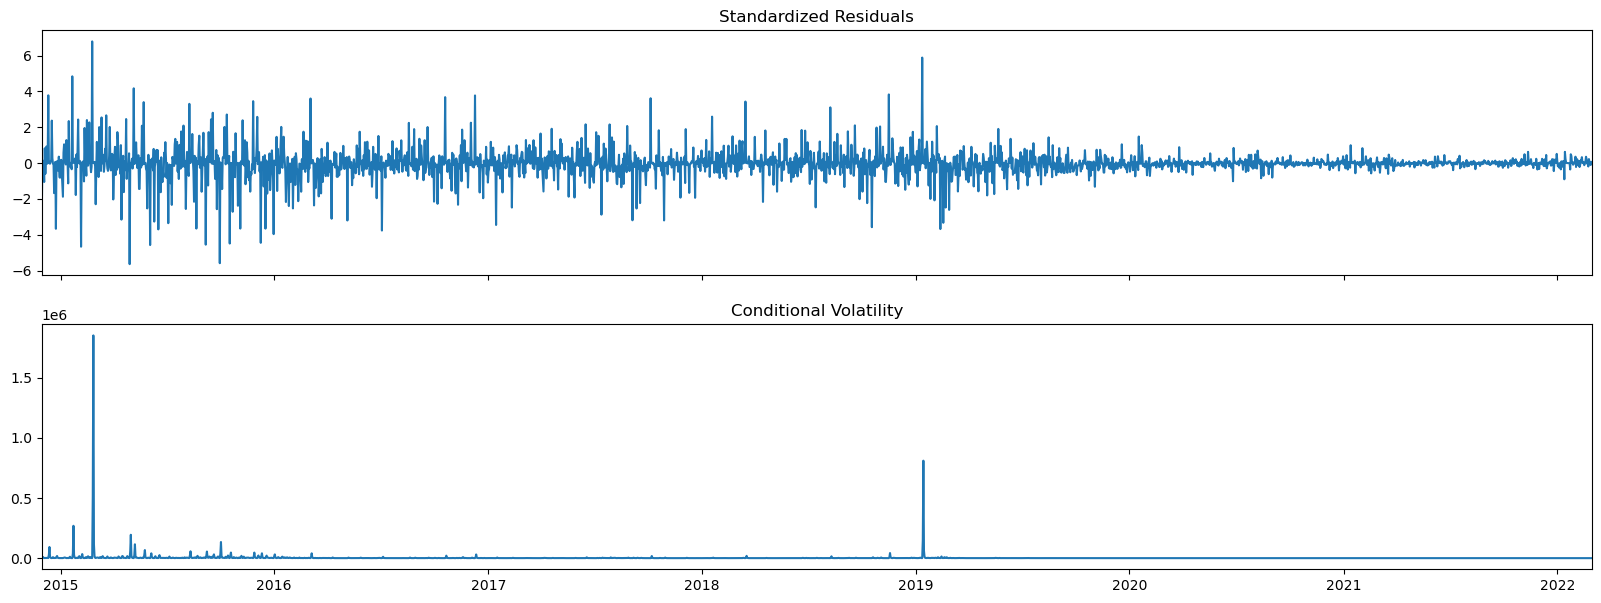

In [84]:
gm_result.plot()
plt.show()

#### Comprobación de la calidad del modelo

Vemos que el valor absoluto de t > 2 y que el p-valor < 0.05 en todos los caso, por lo que podríamos aceptar todos los coeficientes como buenos ajustes. Comprobemos que el residuo del ajuste no tiene autocorrelación.

In [80]:
gm_std_resid = gm_result.std_resid


In [81]:
lm_test = het_arch(gm_std_resid)

print("Resultados del ARCH test:")
print(f"Estadístico LM: {lm_test[0]:.4f}")
print(f"P-valor LM: {lm_test[1]:.4f}")
print(f"Estadístico F: {lm_test[2]:.4f}")
print(f"P-valor F: {lm_test[3]:.4f}")

Resultados del ARCH test:
Estadístico LM: 63.3260
P-valor LM: 0.0000
Estadístico F: 6.4613
P-valor F: 0.0000
